## CLIPScope

Based on original work by Hao Fu, Naman Patel, Prashanth Krishnamurthy and Farshad Khorrami

In [1]:
from pathlib import Path
import numpy as np
import torch
import clip
from datasets import load_dataset
from torch.utils.data import Dataset
from torchvision.datasets import CIFAR10, CIFAR100, SVHN, EuroSAT, FashionMNIST, MNIST, KMNIST

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = Path.cwd()

class ImageNet100(Dataset):
    def __init__(self, root="data", transform=None):
        self.data = load_dataset("parquet", data_files=str(Path(root) / "validation-00000-of-00001.parquet"), split="train")
        self.transform = transform
        self.classes = self.data.features["label"].names

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        image = item["image"].convert("RGB")
        label = int(item["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

def load_clip(name="ViT-B/16"):
    model, preprocess = clip.load(name, DEVICE)
    model.eval()
    return model, preprocess

@torch.no_grad()
def encode_texts(model, prompts, batch_size=256):
    """L2-normalised CLIP text features, computed in batches (CPU tensor out)."""
    feats = []
    for s in range(0, len(prompts), batch_size):
        tokens = clip.tokenize(prompts[s:s+batch_size], truncate=True).to(DEVICE)
        f = model.encode_text(tokens).float()
        f /= f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu())
    return torch.cat(feats)

def get_dataset(name, root="data"):
    """Return a torchvision-style dataset (test split, downloaded if missing)."""
    n = name.lower()
    if n == "cifar100":
        return CIFAR100(root, train=False, download=True)
    if n == "cifar10":
        return CIFAR10(root, train=False, download=True)
    if n == "svhn":
        return SVHN(root, split="test", download=True)
    if n == "eurosat":
        return EuroSAT(root, download=True)
    if n == "fashionmnist":
        return FashionMNIST(root, train=False, download=True)
    if n == "mnist":
        return MNIST(root, train=False, download=True)
    if n == "kmnist":
        return KMNIST(root, train=False, download=True)
    if n == "imagenet100":
        return ImageNet100(root=root)
    raise ValueError(f"Unknown dataset: {name}")

def class_names(x):
    """x: dataset name or dataset object. ImageNetV2 uses imagenet_class_clean.npy."""
    if isinstance(x, str):
        # if x.lower() == "imagenetv2":
        #     return [str(c) for c in np.load(ROOT / "imagenet_class_clean.npy").tolist()]
        x = get_dataset(x)
    return [c.replace("_", " ").lower() for c in x.classes]

In [6]:
import math
import numpy as np
import torch
import nltk
from nltk.corpus import wordnet as wn

def load_nouns():
    path = ROOT / "nouns.pt"
    if path.exists():
        nouns = torch.load(path, weights_only=False)
        print(f"Loaded {len(nouns)} nouns from {path}")
    else:
        nltk.download("wordnet", quiet=True)
        nouns = set()
        for syn in wn.all_synsets("n"):
            for lemma in syn.lemma_names():
                if lemma.isalpha() and lemma.islower():
                    nouns.add(lemma)
        nouns = sorted(nouns)
        torch.save(nouns, path)
        print(f"Built {len(nouns)} WordNet nouns -> {path}")
    return [str(n).replace("_", " ") for n in nouns]

def sort_nouns(id, model_name, eta, drop_id_names=False):
    id_classes = class_names(id)
    nouns = np.array(load_nouns())

    if drop_id_names:
        nouns = np.array([n for n in nouns if n not in set(id_classes)])

    model, preprocess = load_clip(model_name)
    text_features = encode_texts(model, [f"a photo of a {c}" for c in id_classes])

    percentile = max(1, math.ceil(len(id_classes) * eta))
    print(f"ID classes: {len(id_classes)} -> percentile index = {percentile}")

    scores = []
    for s in range(0, len(nouns), 1024):
        sample_features = encode_texts(model, [f"a photo of a {w}" for w in nouns[s:s+1024]])
        similarity = -(sample_features @ text_features.T)
        value, index = torch.kthvalue(similarity, percentile, dim=1)
        scores.append(-value.numpy())
        print(f"  {min(s+1024, len(nouns))}/{len(nouns)}", end="\r")

    scores = np.concatenate(scores).astype(np.float32)
    sorted_indices = np.argsort(scores)
    sorted_nouns = [str(nouns[i]) for i in sorted_indices]

    torch.save(sorted_nouns, ROOT / f"sorted_nouns_{id}.pt")

    print("\nTotal nouns:", len(sorted_nouns))
    print("Lowest-ranked nouns:", sorted_nouns[:10])
    print("Highest-ranked nouns:", sorted_nouns[-10:])
    return sorted_nouns

In [7]:
sorted_nouns = sort_nouns(
    id="imagenet100",
    model_name="ViT-B/16",
    eta=0.05,
    drop_id_names=False
)

Generating train split: 0 examples [00:00, ? examples/s]

Loaded 41492 nouns from c:\Users\achin\Documents\Semester 5 Modules\EN3160 - Image Processing and Machine Vision\CLIPScope\nouns.pt


C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


ID classes: 100 -> percentile index = 5
  41492/41492
Total nouns: 41492
Lowest-ranked nouns: ['prognostic', 'prognostication', 'prognosis', 'caladenia', 'pleurothallis', 'auricula', 'stapelia', 'cecropia', 'archerfish', 'episcia']
Highest-ranked nouns: ['favorite', 'thing', 'item', 'phot', 'entire', 'object', 'whole', 'gadget', 'image', 'device']


In [2]:
import numpy as np
import torch
from sklearn import metrics
from torch.utils.data import DataLoader, Subset

CACHE = ROOT / ".cache"
CACHE.mkdir(exist_ok=True)
G_NAMES = ["p1", "p1/p0", "p2", "p2/p0", "p1*p2", "p1*p2/p0"]

@torch.no_grad()
def image_features(model, preprocess, name, model_name, L, data_seed=0, batch_size=128):
    cache = CACHE / f"{name}_{model_name.replace('/', '')}_{L}_{data_seed}.pt"
    if cache.exists():
        return torch.load(cache, weights_only=False)

    ds = get_dataset(name)
    ds.transform = preprocess
    rng = np.random.RandomState(data_seed)
    idx = rng.permutation(len(ds))[:min(L, len(ds))].tolist()
    feats = []

    for n, (x, _) in enumerate(DataLoader(Subset(ds, idx), batch_size=batch_size)):
        f = model.encode_image(x.to(DEVICE)).float()
        f /= f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu())
        print(f"  [{name}] {min((n+1)*batch_size, len(idx))}/{len(idx)}", end="\r")

    print()
    feats = torch.cat(feats)
    torch.save(feats, cache)
    return feats

def build_text_features(model, id_classes, ood_labels):
    id_f = encode_texts(model, [f"a photo of a {c}" for c in id_classes])
    ood_f = encode_texts(model, [f"a photo of a {c}" for c in ood_labels])
    return torch.cat([id_f, ood_f], 0)

def pick_labels(nouns, M, mode):
    if mode == "both":
        return nouns[:M] + nouns[-M:]
    return nouns[:M] if mode == "farthest" else nouns[-M:]

def make_order(kind, n_id, n_ood, rng):
    n = n_id + n_ood
    if kind == "random":
        return rng.permutation(n)
    if kind == "forward":
        return np.arange(n)
    if kind == "backward":
        return np.r_[np.arange(n_id, n), np.arange(n_id)]
    raise ValueError(f"Unknown order: {kind}")

def stream(id_f, ood_f, text_f, n_id, order):
    x = torch.cat([id_f, ood_f], 0)
    y = np.concatenate([np.zeros(len(id_f)), np.ones(len(ood_f))])
    sim = 100 * (x @ text_f.T)
    probs_id = sim[:, :n_id].softmax(dim=-1)
    p2 = sim.softmax(dim=-1)[:, :n_id].sum(dim=-1).numpy()
    count = torch.ones(n_id)
    p1, p0 = np.zeros(len(y)), np.zeros(len(y))

    for i in order:
        pred = probs_id[i].argmax()
        p1[i] = probs_id[i, pred].item()
        p0[i] = (count[pred] / count.sum()).item()
        count[pred] += 1

    return p1, p2, p0, y

def g_variants(p1, p2, p0):
    return {
        "p1": p1,
        "p1/p0": p1 / p0,
        "p2": p2,
        "p2/p0": p2 / p0,
        "p1*p2": p1 * p2,
        "p1*p2/p0": p1 * p2 / p0
    }

def evaluate(scores, labels):
    fpr, tpr, _ = metrics.roc_curve(labels, scores, pos_label=0)
    auroc = metrics.auc(fpr, tpr)
    valid = np.flatnonzero(tpr > 0.95)
    fpr95 = fpr[valid[0]] if len(valid) else np.nan
    return auroc, fpr95

def main(id, ood, L, M, labels, orders, trials, model_name):
    path = ROOT / f"sorted_nouns_{id}.pt"
    if not path.exists():
        raise FileNotFoundError(f"{path} missing - run noun mining first")

    nouns = torch.load(path, weights_only=False)
    id_classes = class_names(id)
    n_id = len(id_classes)
    M = M or 5 * n_id
    ood_labels = pick_labels(nouns, M, labels)

    model, preprocess = load_clip(model_name)
    text_f = build_text_features(model, id_classes, ood_labels)

    print(f"device={DEVICE} ID classes={n_id} OOD labels={len(ood_labels)} (M={M}, {labels})")

    id_f = image_features(model, preprocess, id, model_name, L)

    all_results = {}

    for kind in orders:
        n_trials = trials if kind == "random" else 1
        all_results[kind] = {}

        for ood_name in ood:
            ood_f = image_features(model, preprocess, ood_name, model_name, L)
            res = {g: [] for g in G_NAMES}

            for t in range(n_trials):
                order = make_order(kind, len(id_f), len(ood_f), np.random.RandomState(t))
                p1, p2, p0, y = stream(id_f, ood_f, text_f, n_id, order)

                for g, s in g_variants(p1, p2, p0).items():
                    res[g].append(evaluate(s, y))

            print(f"\n== {kind} order | ID={id} OOD={ood_name} (ID n={len(id_f)}, OOD n={len(ood_f)}, trials={n_trials}) ==")

            all_results[kind][ood_name] = {}

            for g in G_NAMES:
                a = np.array(res[g]) * 100
                auroc_mean = a[:, 0].mean()
                fpr95_mean = a[:, 1].mean()

                all_results[kind][ood_name][g] = {
                    "AUROC": auroc_mean,
                    "FPR95": fpr95_mean,
                    "AUROC_std": a[:, 0].std(),
                    "FPR95_std": a[:, 1].std()
                }

                print(f"g = {g:9s} AUROC {auroc_mean:6.2f} FPR95 {fpr95_mean:6.2f}")

    return all_results

In [5]:
results_cifar100 = main(
    id="cifar100",
    ood=["svhn", "fashionmnist", "kmnist"],
    L=4000,
    M=None,
    labels="both",
    orders=["random", "forward", "backward"],
    trials=5,
    model_name="ViT-B/16"
)

C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")
C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


device=cuda ID classes=100 OOD labels=1000 (M=500, both)

== random order | ID=cifar100 OOD=svhn (ID n=4000, OOD n=4000, trials=5) ==
g = p1        AUROC  83.51 FPR95  85.78
g = p1/p0     AUROC  98.45 FPR95   7.70
g = p2        AUROC  64.99 FPR95  99.88
g = p2/p0     AUROC  96.30 FPR95  17.73
g = p1*p2     AUROC  76.62 FPR95  96.95
g = p1*p2/p0  AUROC  97.01 FPR95  15.77

== random order | ID=cifar100 OOD=fashionmnist (ID n=4000, OOD n=4000, trials=5) ==
g = p1        AUROC  74.28 FPR95  79.10
g = p1/p0     AUROC  97.68 FPR95  12.04
g = p2        AUROC  79.41 FPR95  93.73
g = p2/p0     AUROC  96.17 FPR95  21.48
g = p1*p2     AUROC  79.71 FPR95  84.88
g = p1*p2/p0  AUROC  97.27 FPR95  14.78

== random order | ID=cifar100 OOD=kmnist (ID n=4000, OOD n=4000, trials=5) ==
g = p1        AUROC  95.19 FPR95  29.90
g = p1/p0     AUROC  98.59 FPR95   6.42
g = p2        AUROC  88.73 FPR95  85.45
g = p2/p0     AUROC  97.15 FPR95  16.58
g = p1*p2     AUROC  95.39 FPR95  28.12
g = p1*p2/p0  AUROC  9

In [3]:
results_imagenet100 = main(
    id="imagenet100",
    ood=["svhn", "fashionmnist", "kmnist"],
    L=2000,
    M=None,
    labels="both",
    orders=["random", "forward", "backward"],
    trials=5,
    model_name="ViT-B/16"
)

C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


device=cuda ID classes=100 OOD labels=1000 (M=500, both)
  [imagenet100] 2000/2000

== random order | ID=imagenet100 OOD=svhn (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AUROC  99.01 FPR95   4.90
g = p1/p0     AUROC  99.41 FPR95   2.34
g = p2        AUROC  95.32 FPR95  35.80
g = p2/p0     AUROC  98.82 FPR95   4.97
g = p1*p2     AUROC  98.10 FPR95   4.30
g = p1*p2/p0  AUROC  99.55 FPR95   0.75

== random order | ID=imagenet100 OOD=fashionmnist (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AUROC  98.30 FPR95   9.75
g = p1/p0     AUROC  98.56 FPR95   8.43
g = p2        AUROC  90.71 FPR95  94.10
g = p2/p0     AUROC  95.86 FPR95  27.41
g = p1*p2     AUROC  95.71 FPR95  25.95
g = p1*p2/p0  AUROC  98.06 FPR95   8.79

== random order | ID=imagenet100 OOD=kmnist (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AUROC  99.53 FPR95   2.25
g = p1/p0     AUROC  99.55 FPR95   1.36
g = p2        AUROC  92.17 FPR95  88.50
g = p2/p0     AUROC  98.01 FPR95   9.38
g = p1*p2     AUROC  97.51 

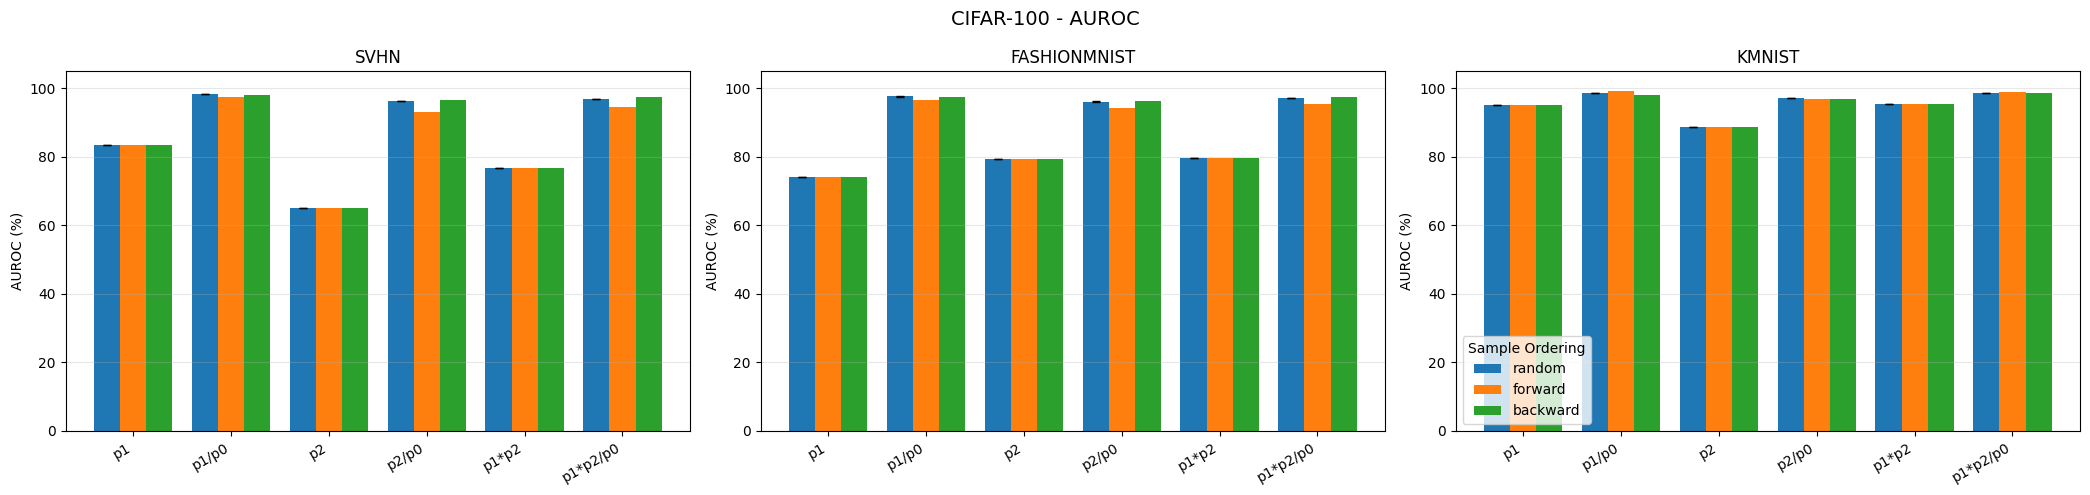

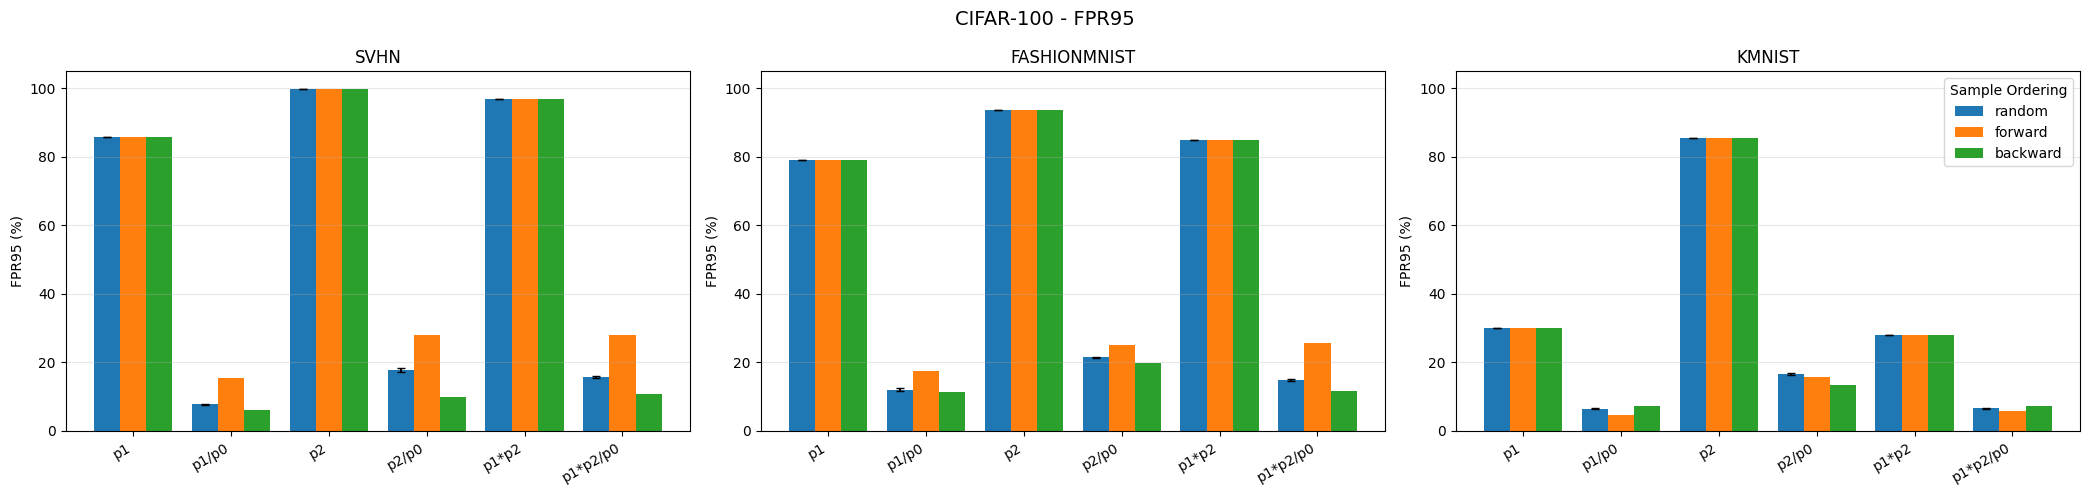

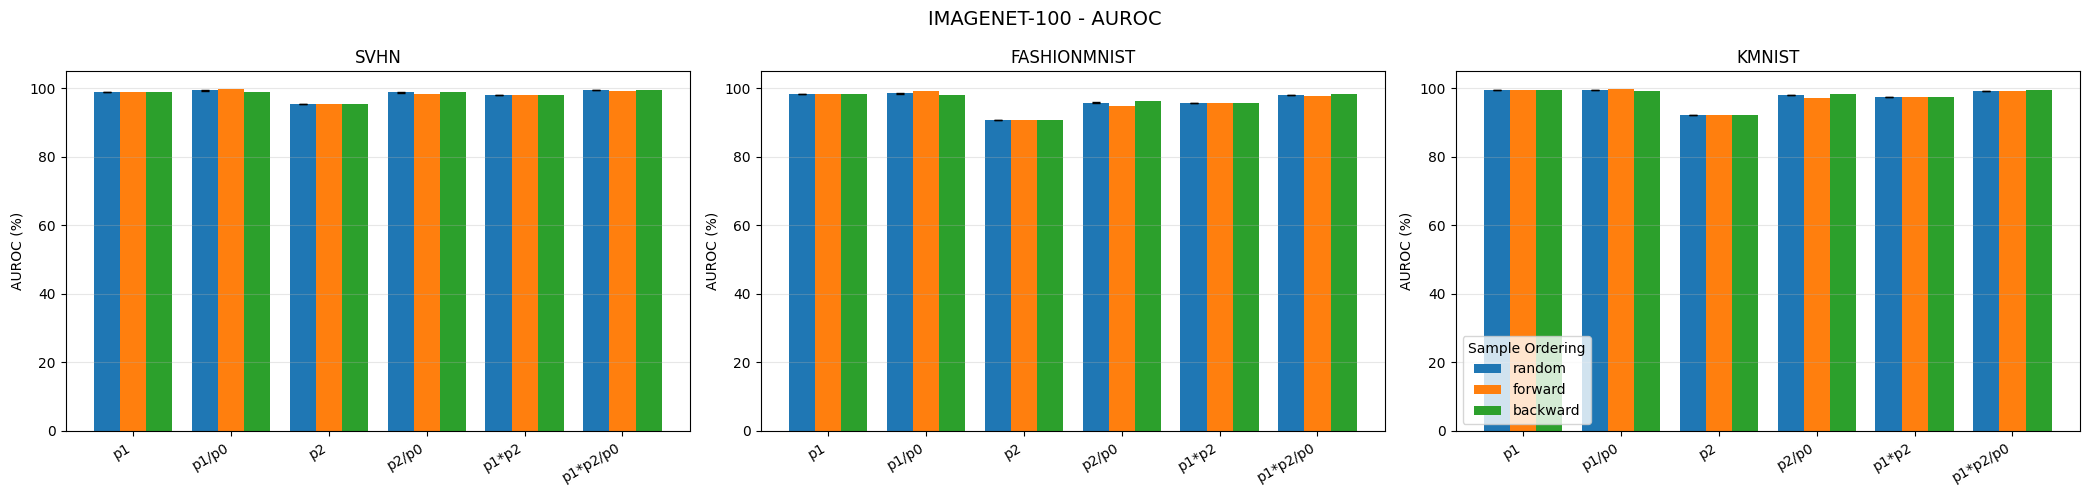

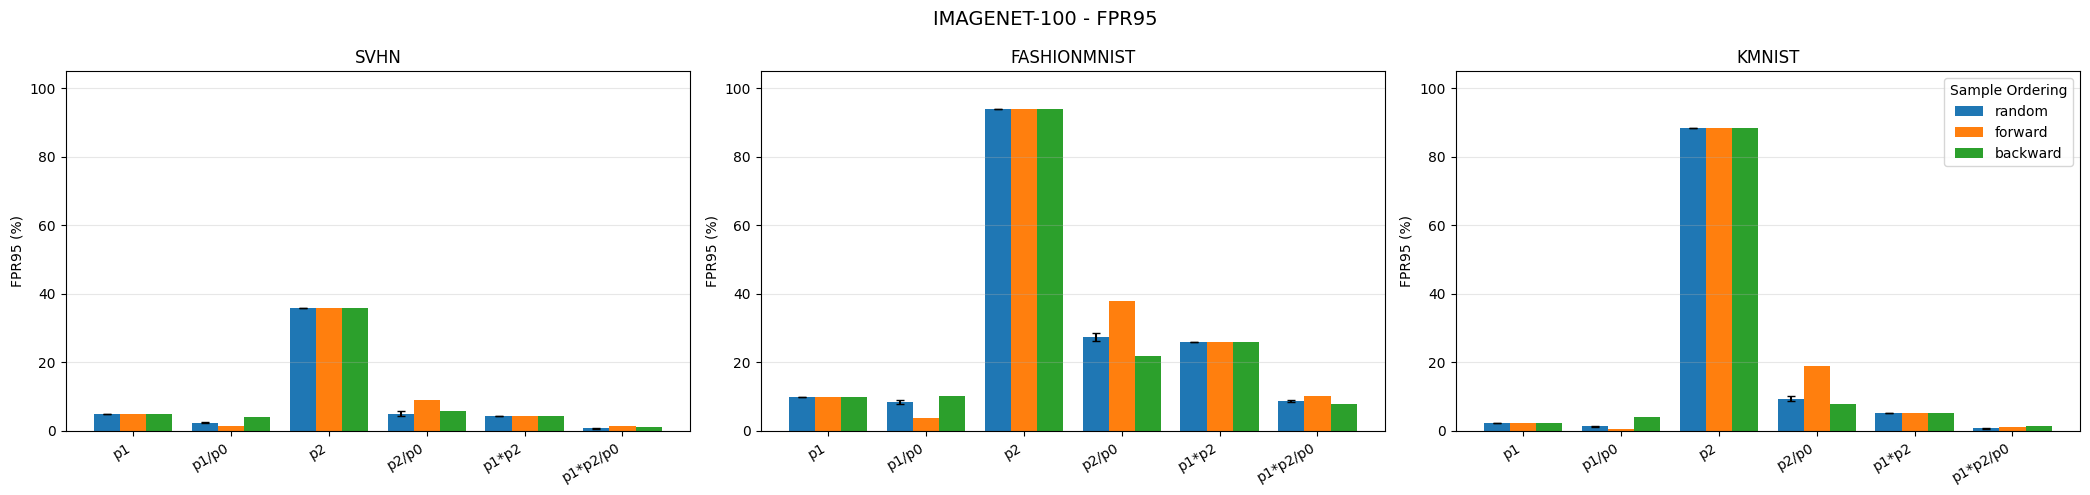

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_experiments(experiments):
    for experiment_name, result in experiments.items():
        orders = list(result.keys())
        ood_datasets = list(result[orders[0]].keys())
        methods = list(result[orders[0]][ood_datasets[0]].keys())

        for metric in ["AUROC", "FPR95"]:
            fig, axes = plt.subplots(1, len(ood_datasets), figsize=(7 * len(ood_datasets), 5))
            axes = np.atleast_1d(axes)
            x = np.arange(len(methods))
            width = 0.8 / len(orders)

            for j, ood_name in enumerate(ood_datasets):
                ax = axes[j]

                for i, order in enumerate(orders):
                    values = [
                        result[order][ood_name][method][metric]
                        for method in methods
                    ]

                    errors = [
                        result[order][ood_name][method][f"{metric}_std"]
                        for method in methods
                    ]

                    offset = (i - (len(orders) - 1) / 2) * width

                    ax.bar(
                        x + offset,
                        values,
                        width,
                        yerr=errors if order == "random" else None,
                        capsize=3,
                        label=order
                    )

                ax.set_title(ood_name.upper())
                ax.set_ylabel(f"{metric} (%)")
                ax.set_xticks(x)
                ax.set_xticklabels(methods, rotation=30, ha="right")
                ax.set_ylim(0, 105)
                ax.grid(axis="y", alpha=0.3)

            axes[-1].legend(title="Sample Ordering")
            fig.suptitle(f"{experiment_name} - {metric}", fontsize=14)
            plt.tight_layout()
            plt.show()
                
experiments = {
    "CIFAR-100": results_cifar100,
    "IMAGENET-100": results_imagenet100
}

plot_experiments(experiments)

In [8]:
import torch

id_labels = class_names("imagenet100")

model, _ = load_clip("ViT-B/16")

id_features = encode_texts(
    model,
    [f"a photo of a {c}" for c in id_labels]
)

selected = (
    sorted_nouns[:10] +
    sorted_nouns[-10:]
)

noun_features = encode_texts(
    model,
    [f"the {noun}" for noun in selected]
)

similarities = noun_features @ id_features.T

for i, noun in enumerate(selected):
    values, indices = torch.topk(similarities[i], k=5)

    print(f"\n{noun}")
    for value, index in zip(values, indices):
        print(f"  {id_labels[index.item()]:20s} {value.item():.4f}")


prognostic
  wild boar, boar, sus scrofa 0.7385
  tripod               0.7363
  cinema, movie theater, movie theatre, movie house, picture palace 0.7221
  throne               0.7193
  pickup, pickup truck 0.7180

prognostication
  tripod               0.7510
  cinema, movie theater, movie theatre, movie house, picture palace 0.7451
  wild boar, boar, sus scrofa 0.7446
  throne               0.7444
  pickup, pickup truck 0.7402

prognosis
  tripod               0.7523
  wild boar, boar, sus scrofa 0.7502
  cinema, movie theater, movie theatre, movie house, picture palace 0.7417
  throne               0.7399
  pickup, pickup truck 0.7381

caladenia
  milk can             0.4237
  chihuahua            0.4226
  boxer                0.4149
  shih-tzu             0.4126
  garter snake, grass snake 0.4076

pleurothallis
  leafhopper           0.4567
  doberman, doberman pinscher 0.4168
  toy terrier          0.4089
  pineapple, ananas    0.4025
  garter snake, grass snake 0.4021

auricula
 